In [26]:
import os

os.makedirs("/content/PlantDisease", exist_ok=True)

print("Folder created successfully!")

Folder created successfully!


In [27]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle (1).json


In [ ]:
import os

os.makedirs("/root/.kaggle", exist_ok=True)

!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle API configured!")

In [ ]:
!kaggle datasets list -s plantvillage

In [ ]:
!kaggle datasets download -d aarishasifkhan/plantvillage-potato-disease-dataset

In [ ]:
import zipfile
import os

zip_path = "/content/plantvillage-potato-disease-dataset.zip"
extract_path = "/content/PlantDisease"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

In [ ]:
print(os.listdir("/content/PlantDisease"))

In [ ]:
dataset_path = "/content/PlantDisease/PlantVillage"

print(os.listdir(dataset_path))

In [ ]:
import os

dataset_path = "/content/PlantDisease/PlantVillage"

for class_name in os.listdir(dataset_path):
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        images = os.listdir(class_path)
        print(class_name, ":", len(images), "images")

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

dataset_path = "/content/PlantDisease/PlantVillage"

classes = os.listdir(dataset_path)

plt.figure(figsize=(12, 4))

for i, class_name in enumerate(classes):
    class_path = os.path.join(dataset_path, class_name)

    image_name = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    plt.subplot(1, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.show()

In [ ]:
import os
import shutil
import random

original_path = "/content/PlantDisease/PlantVillage"
balanced_path = "/content/PlantDisease/Balanced"

# Create balanced dataset folder
os.makedirs(balanced_path, exist_ok=True)

classes = os.listdir(original_path)

for class_name in classes:

    source_folder = os.path.join(original_path, class_name)
    destination_folder = os.path.join(balanced_path, class_name)

    os.makedirs(destination_folder, exist_ok=True)

    # Get all images
    images = os.listdir(source_folder)

    # Select 152 images randomly
    selected_images = random.sample(images, 152)

    # Copy selected images
    for image in selected_images:
        source = os.path.join(source_folder, image)
        destination = os.path.join(destination_folder, image)
        shutil.copy2(source, destination)

print("Balanced dataset created successfully!")

In [ ]:
balanced_path = "/content/PlantDisease/Balanced"

for class_name in os.listdir(balanced_path):
    class_path = os.path.join(balanced_path, class_name)

    print(class_name, ":", len(os.listdir(class_path)), "images")

In [ ]:
import os

base_path = "/content/PlantDisease/Balanced"

train_path = "/content/PlantDisease/train"
val_path = "/content/PlantDisease/validation"
test_path = "/content/PlantDisease/test"

for path in [train_path, val_path, test_path]:
    os.makedirs(path, exist_ok=True)

print("Train, validation and test folders created!")

In [ ]:
import os
import shutil
import random

random.seed(42)

classes = os.listdir(base_path)

for class_name in classes:

    source_folder = os.path.join(base_path, class_name)

    train_folder = os.path.join(train_path, class_name)
    val_folder = os.path.join(val_path, class_name)
    test_folder = os.path.join(test_path, class_name)

    os.makedirs(train_folder, exist_ok=True)
    os.makedirs(val_folder, exist_ok=True)
    os.makedirs(test_folder, exist_ok=True)

    images = os.listdir(source_folder)
    random.shuffle(images)

    total = len(images)

    train_end = int(0.70 * total)
    val_end = int(0.85 * total)

    train_images = images[:train_end]
    val_images = images[train_end:val_end]
    test_images = images[val_end:]

    for image in train_images:
        shutil.copy2(
            os.path.join(source_folder, image),
            os.path.join(train_folder, image)
        )

    for image in val_images:
        shutil.copy2(
            os.path.join(source_folder, image),
            os.path.join(val_folder, image)
        )

    for image in test_images:
        shutil.copy2(
            os.path.join(source_folder, image),
            os.path.join(test_folder, image)
        )

print("Dataset split completed!")

In [ ]:
for name, path in [
    ("Training", train_path),
    ("Validation", val_path),
    ("Testing", test_path)
]:

    print("\n", name)

    for class_name in os.listdir(path):
        class_path = os.path.join(path, class_name)
        print(class_name, ":", len(os.listdir(class_path)))

In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Datasets loaded successfully!")

In [ ]:
print("Classes:", train_data.class_names)

In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

normalization = layers.Rescaling(1./255)

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    normalization,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dense(3, activation="softmax")
])

model.summary()

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

In [ ]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)


In [ ]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

for images, labels in test_data:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

print(cm)

In [ ]:
class_names = test_data.class_names

print(class_names)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

In [ ]:
from google.colab import files

uploaded = files.upload()

In [30]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

# Upload image
from google.colab import files
uploaded = files.upload()

# Get uploaded image name
image_path = list(uploaded.keys())[0]

# Load image
img = load_img(
    image_path,
    target_size=(224, 224)
)

# Convert image to array
img_array = img_to_array(img)

# Add batch dimension
img_array = np.expand_dims(
    img_array,
    axis=0
)

# IMPORTANT:
# Do NOT divide by 255 here.
# Your model already has Rescaling(1./255)

# Predict
prediction = model.predict(
    img_array,
    verbose=0
)[0]

# Exact class order from your notebook
class_names = [
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy'
]

# Get predicted class
predicted_index = np.argmax(prediction)

predicted_class = class_names[predicted_index]

confidence = prediction[predicted_index] * 100

print("================================")
print("       POTATO DISEASE RESULT")
print("================================")

print("Prediction:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

print("\nAll probabilities:")

for i in range(len(class_names)):
    print(
        class_names[i],
        ":",
        round(prediction[i] * 100, 2),
        "%"
    )

Saving f7db505f-aabe-4b96-b719-8c930b5ff471___RS_Early.B 9224.JPG to f7db505f-aabe-4b96-b719-8c930b5ff471___RS_Early.B 9224.JPG
       POTATO DISEASE RESULT
Prediction: Potato___Early_blight
Confidence: 99.08 %

All probabilities:
Potato___Early_blight : 99.08 %
Potato___Late_blight : 0.92 %
Potato___healthy : 0.0 %


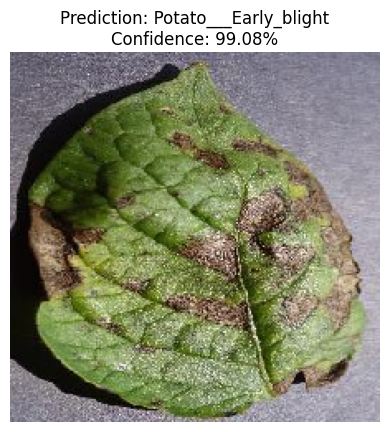

In [31]:
import matplotlib.pyplot as plt

plt.imshow(img)
plt.axis("off")
plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()